# Model Comparison & Actuarial Metrics (Double Lift & Calibration)

This notebook performs the comprehensive actuarial evaluation to answer the central research question:
1. **Ordered Lorenz Curves & Gini Indices:** Measuring cumulative loss concentration and risk discrimination.
2. **Double Lift Chart:** The gold standard in insurance pricing — evaluating empirical loss costs across deciles of the ratio $(\hat{\pi}_{\text{XGB}} / \hat{\pi}_{\text{GLM}})$.
3. **Calibration Quality:** Decile calibration curves and Root Mean Squared Calibration Error (RMSCE).
4. **Subgroup Slice & Robustness:** Evaluating performance stability across driver age segments and geographic territories.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.models import (
    FrequencyPoissonGLM,
    SeverityGammaGLM,
    TwoPartGLM,
    FrequencyPoissonXGB,
    SeverityGammaXGB,
    TwoPartXGB,
)
from src.evaluation import (
    poisson_deviance,
    gamma_deviance,
    tweedie_deviance,
    gini_coefficient,
    compute_double_lift,
    compute_calibration_table,
    compute_rmsce,
    compute_lorenz_curve,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 1. Train Models & Generate Out-of-Sample Predictions

In [2]:
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
train_full, test_df = train_test_split(df, test_size=0.20, random_state=42, shuffle=True)
train_df, val_df = train_test_split(train_full, test_size=0.125, random_state=42, shuffle=True)

# 1. Baseline GLMs
glm_freq = FrequencyPoissonGLM().fit(train_full, offset_col="LogExposure")
glm_sev = SeverityGammaGLM().fit(train_full)
twopart_glm = TwoPartGLM(glm_freq, glm_sev)

# 2. Champion XGBoost Models
xgb_freq = FrequencyPoissonXGB(max_depth=4, learning_rate=0.05, n_estimators=300, min_child_weight=20.0, enforce_monotonic_bm=True)
xgb_freq.fit(train_df, df_val=val_df, early_stopping_rounds=25)
xgb_sev = SeverityGammaXGB().fit(train_full)
twopart_xgb = TwoPartXGB(xgb_freq, xgb_sev)

# Generate Pure Premium on Test Set
eval_df = test_df.copy()
eval_df["Pred_GLM_Pure"] = twopart_glm.predict_pure_premium(test_df)
eval_df["Pred_XGB_Pure"] = twopart_xgb.predict_pure_premium(test_df)

print(f"Evaluated on {len(eval_df):,} test policies ({eval_df['Exposure_Capped'].sum():,.1f} policy years)")
print(f"GLM Mean Pure Premium: €{eval_df['Pred_GLM_Pure'].mean():.2f}")
print(f"XGB Mean Pure Premium: €{eval_df['Pred_XGB_Pure'].mean():.2f}")

Evaluated on 135,603 test policies (71,775.1 policy years)
GLM Mean Pure Premium: €188.45
XGB Mean Pure Premium: €193.50


## 2. Ordered Lorenz Curves & Gini Comparison

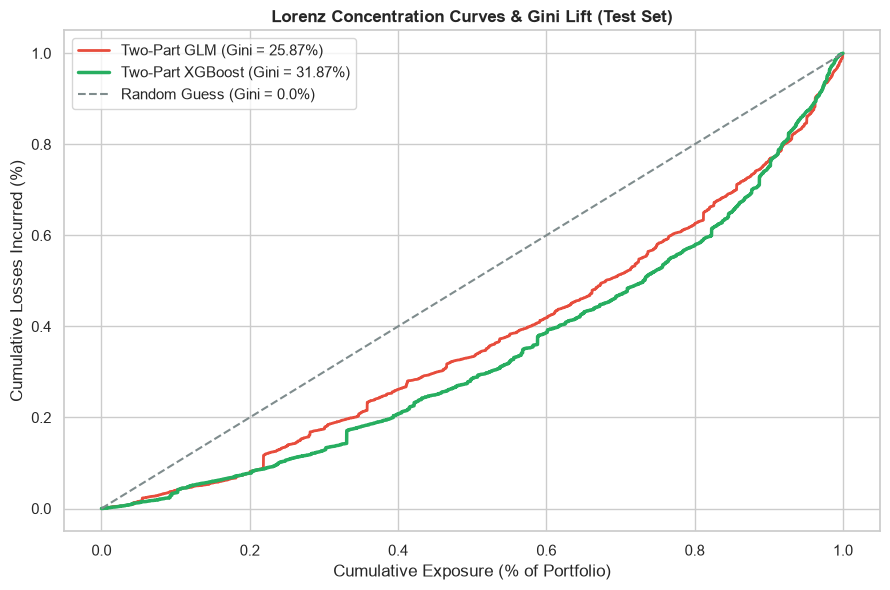

In [3]:
# Compute Lorenz curves
w_glm, l_glm = compute_lorenz_curve(eval_df["PurePremium"], eval_df["Pred_GLM_Pure"], exposure=eval_df["Exposure_Capped"])
w_xgb, l_xgb = compute_lorenz_curve(eval_df["PurePremium"], eval_df["Pred_XGB_Pure"], exposure=eval_df["Exposure_Capped"])

gini_glm = gini_coefficient(eval_df["PurePremium"], eval_df["Pred_GLM_Pure"], exposure=eval_df["Exposure_Capped"])
gini_xgb = gini_coefficient(eval_df["PurePremium"], eval_df["Pred_XGB_Pure"], exposure=eval_df["Exposure_Capped"])

plt.figure(figsize=(9, 6))
plt.plot(w_glm, l_glm, color="#e74c3c", lw=2, label=f"Two-Part GLM (Gini = {gini_glm*100:.2f}%)")
plt.plot(w_xgb, l_xgb, color="#27ae60", lw=2.5, label=f"Two-Part XGBoost (Gini = {gini_xgb*100:.2f}%)")
plt.plot([0, 1], [0, 1], color="#7f8c8d", linestyle="--", lw=1.5, label="Random Guess (Gini = 0.0%)")

plt.title("Lorenz Concentration Curves & Gini Lift (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Cumulative Exposure (% of Portfolio)")
plt.ylabel("Cumulative Losses Incurred (%)")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 3. Actuarial Double Lift Chart (XGBoost vs GLM)

The **Double Lift Chart** sorts all test policies by the ratio $r_i = \frac{\hat{\pi}_{\text{XGB}}}{\hat{\pi}_{\text{GLM}}}$ into 10 buckets:
- **Bucket 1:** Policies where XGBoost predicts much lower risk than GLM (GLM overpriced them).
- **Bucket 10:** Policies where XGBoost predicts much higher risk than GLM (GLM underpriced them).
- **Validation:** If XGBoost is superior, the empirical observed losses (**dark blue line**) will follow the XGBoost curve (**green line**) across all 10 buckets.

,Bucket,Policies,Exposure,Avg_Ratio_XGB_over_GLM,Observed_Pure_Premium,Challenger_Pure_Premium,Baseline_Pure_Premium,Loss_Ratio_Challenger,Loss_Ratio_Baseline
0,1,13561,6127.876774,0.543675,140.811999,149.120830,285.401346,0.944281,0.493382
1,2,13560,7066.187272,0.678444,135.180046,134.488941,198.358274,1.005139,0.681494
2,3,13560,7412.018549,0.758547,120.682782,133.303927,175.800963,0.905321,0.686474
3,4,13560,7695.217785,0.827109,119.125612,133.559937,161.587935,0.891926,0.737218
4,5,13561,7833.024988,0.890327,127.519605,134.864684,151.488869,0.945537,0.841775
5,6,13560,7883.345675,0.954732,101.603893,138.750895,145.336242,0.732276,0.699095
6,7,13560,7859.566980,1.024474,120.820794,143.890835,140.519664,0.839670,0.859814
7,8,13560,7636.430915,1.111914,208.982372,154.496017,138.985138,1.352672,1.503631
8,9,13560,6951.546069,1.249494,137.591293,188.785177,151.049108,0.728825,0.910904
9,10,13561,5309.868297,5.054605,271.890761,441.621993,207.608423,0.615664,1.309633


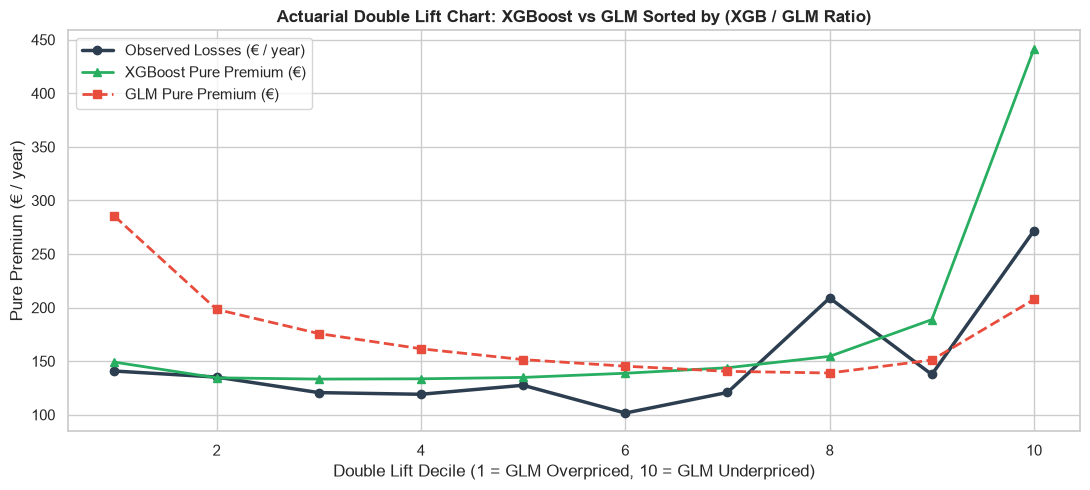

In [4]:
double_lift_df = compute_double_lift(
    eval_df,
    pred_challenger_col="Pred_XGB_Pure",
    pred_baseline_col="Pred_GLM_Pure",
    target_loss_col="TotalClaimAmount",
    exposure_col="Exposure_Capped",
    n_bins=10
)
display(double_lift_df)

plt.figure(figsize=(11, 5))
plt.plot(double_lift_df["Bucket"], double_lift_df["Observed_Pure_Premium"], marker="o", lw=2.5, color="#2c3e50", label="Observed Losses (€ / year)")
plt.plot(double_lift_df["Bucket"], double_lift_df["Challenger_Pure_Premium"], marker="^", lw=2, linestyle="-", color="#27ae60", label="XGBoost Pure Premium (€)")
plt.plot(double_lift_df["Bucket"], double_lift_df["Baseline_Pure_Premium"], marker="s", lw=2, linestyle="--", color="#e74c3c", label="GLM Pure Premium (€)")

plt.title("Actuarial Double Lift Chart: XGBoost vs GLM Sorted by (XGB / GLM Ratio)", fontsize=12, fontweight="bold")
plt.xlabel("Double Lift Decile (1 = GLM Overpriced, 10 = GLM Underpriced)")
plt.ylabel("Pure Premium (€ / year)")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 4. Calibration & RMSCE (Root Mean Squared Calibration Error)

In [5]:
calib_glm = compute_calibration_table(eval_df, pred_col="Pred_GLM_Pure")
calib_xgb = compute_calibration_table(eval_df, pred_col="Pred_XGB_Pure")

rmsce_glm = compute_rmsce(calib_glm)
rmsce_xgb = compute_rmsce(calib_xgb)

calib_metrics = pd.DataFrame({
    "Model": ["Two-Part GLM", "Two-Part XGBoost"],
    "RMSCE (Calibration Error in €)": [f"€{rmsce_glm:.2f}", f"€{rmsce_xgb:.2f}"],
    "Gini Index (%)": [f"{gini_glm*100:.2f}%", f"{gini_xgb*100:.2f}%"]
})
display(calib_metrics)

,Model,RMSCE (Calibration Error in €),Gini Index (%)
0,Two-Part GLM,€36.99,25.87%
1,Two-Part XGBoost,€64.16,31.87%


## 5. Subgroup Stability & Slice Analysis

We evaluate model performance across demographic risk slices to verify subgroup calibration.

In [6]:
eval_df["AgeGroup"] = pd.cut(eval_df["DrivAge"], bins=[17, 25, 65, 100], labels=["Young (18-25)", "Adult (26-65)", "Senior (66+)"])

age_slice = eval_df.groupby("AgeGroup").apply(
    lambda g: pd.Series({
        "Policies": len(g),
        "Observed_Pure_Premium": g["TotalClaimAmount"].sum() / g["Exposure_Capped"].sum(),
        "GLM_Pure_Premium": np.average(g["Pred_GLM_Pure"], weights=g["Exposure_Capped"]),
        "XGB_Pure_Premium": np.average(g["Pred_XGB_Pure"], weights=g["Exposure_Capped"]),
    })
).reset_index()

display(age_slice)

# Area code slice
area_slice = eval_df.groupby("Area").apply(
    lambda g: pd.Series({
        "Policies": len(g),
        "Observed_Pure_Premium": g["TotalClaimAmount"].sum() / g["Exposure_Capped"].sum(),
        "GLM_Pure_Premium": np.average(g["Pred_GLM_Pure"], weights=g["Exposure_Capped"]),
        "XGB_Pure_Premium": np.average(g["Pred_XGB_Pure"], weights=g["Exposure_Capped"]),
    })
).reset_index()

display(area_slice)

,AgeGroup,Policies,Observed_Pure_Premium,GLM_Pure_Premium,XGB_Pure_Premium
0,Young (18-25),7863.0,339.976540,311.430922,306.513792
1,Adult (26-65),114409.0,133.562080,166.966456,160.916384
2,Senior (66+),13331.0,146.156019,154.463268,157.604090


,Area,Policies,Observed_Pure_Premium,GLM_Pure_Premium,XGB_Pure_Premium
0,A,20670.0,118.703478,134.261177,132.839314
1,B,15140.0,103.940452,152.791530,146.971339
2,C,38472.0,111.779425,155.303327,153.981759
3,D,30449.0,158.630654,192.762465,185.689477
4,E,27217.0,225.873456,221.404506,209.159474
5,F,3655.0,206.938054,191.421525,198.490662
